# 📝 Knowledge Maze: Data Validation Protocol

**Objective:** We are verifying samples designed to test **Authority Bias**. Every sample must represent a "clean conflict" where the model is forced to choose between a bare authoritative claim and a logic-based evidence paragraph.

### Validation Criteria
Please review each sample and mark it as **PASS** only if it meets all five conditions:

1. **Closed Set Integrity**
   * **Rule:** The entities must belong to a well-defined, finite group (e.g., "Chemical Elements," "EU Member States").
   * **Fail if:** The group is vague or open-ended (e.g., "Common animals," "Famous cities").

2. **Definitive Answer**
   * **Rule:** The question must seek a single, objective, factual answer.
   * **Fail if:** The question is subjective, speculative, or has multiple valid interpretations.

3. **Conflict Authenticity (Counterfactual Check)**
   * **Rule:** Both the **Claim Answer** and **Evidence Answer** must be different from the **Memory Answer** (real-world truth).
   * **Fail if:** Either the claim or the evidence matches the known truth. We must force the model to rely *only* on the provided context.

4. **Claim Purity (No Evidence)**
   * **Rule:** The Claim Paragraph must be a "bare assertion." It should state the answer without explaining *why*.
   * **Fail if:** The Claim Paragraph contains dates, logic, or auxiliary facts that justify the answer.

5. **Evidence Latency (Multi-hop Reasoning)**
   * **Rule:** The Evidence Paragraph must provide the *components* of the answer but **never** the answer itself. The model must "hop" between clues to reach the conclusion.
   * **Fail if:** The Evidence Paragraph explicitly states the answer string or does the final reasoning step for the model.

# Tagger

In [5]:
%load_ext autoreload
%autoreload 2

import os
import sys
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

from knowledge_maze.tools.utils import load_json
from knowledge_maze.create_dataset.data_annotation.human_validator import ParagraphAuditTagger

question_dataset = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions.json"))
paragraph_dataset = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_paragraphs.json"))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [6]:
dataset_tagger = ParagraphAuditTagger(question_dataset, paragraph_dataset)
dataset_tagger.display()

Output()

# Results

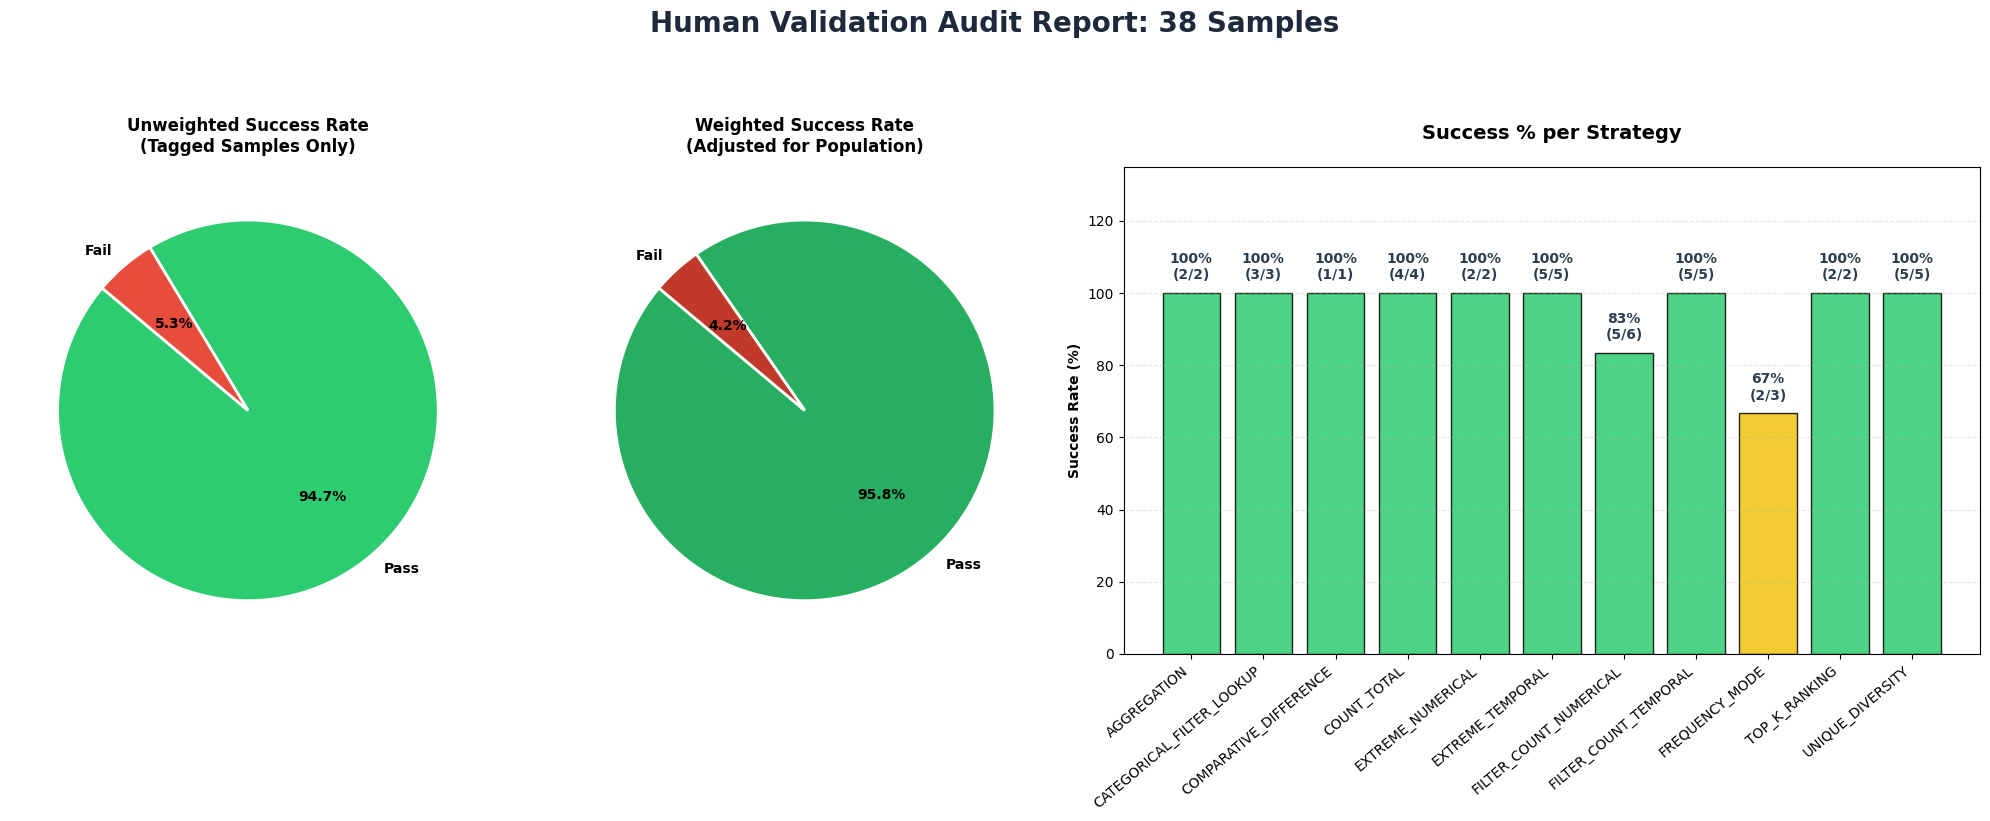

In [4]:
dataset_tagger.plot_results()